<a href="https://colab.research.google.com/github/musamuheke17/FED_Final_Project/blob/main/KinesisIQ_Week1_Sentiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# CELL 1: Import libraries

import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import joblib

SEED = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:

# CELL 2: Download the official dataset files

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "cardiffnlp/tweeteval/main/datasets/sentim`ent/"
)

DATA_DIR = "/content/tweeteval_sentiment"
os.makedirs(DATA_DIR, exist_ok=True)

files = [
    "train_text.txt", "train_labels.txt",
    "val_text.txt", "val_labels.txt",
    "test_text.txt", "test_labels.txt",
    "mapping.txt"
]

for filename in files:
    url = BASE_URL + filename
    destination = os.path.join(DATA_DIR, filename)
    urllib.request.urlretrieve(url, destination)
    print("Downloaded:", filename)

print("Dataset download complete.")


Downloaded: train_text.txt
Downloaded: train_labels.txt
Downloaded: val_text.txt
Downloaded: val_labels.txt
Downloaded: test_text.txt
Downloaded: test_labels.txt
Downloaded: mapping.txt
Dataset download complete.


In [ ]:

# CELL 3: Inspect the label mapping

mapping_path = os.path.join(DATA_DIR, "mapping.txt")

with open(mapping_path, "r", encoding="utf-8") as f:
    print(f.read())


0	negative
1	neutral
2	positive



In [ ]:

# CELL 4: Load data while preserving line order

def load_split(split):
    text_path = os.path.join(
        DATA_DIR, f"{split}_text.txt"
    )
    label_path = os.path.join(
        DATA_DIR, f"{split}_labels.txt"
    )

    with open(text_path, encoding="utf-8") as f:
        texts = f.read().splitlines()

    with open(label_path, encoding="utf-8") as f:
        labels = f.read().splitlines()

    assert len(texts) == len(labels), (
        f"Mismatch in {split}: "
        f"{len(texts)} texts vs {len(labels)} labels"
    )

    return pd.DataFrame({
        "text": texts,
        "label": labels
    })

train_df = load_split("train")
val_df = load_split("val")
test_df = load_split("test")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())


Training shape: (45615, 2)
Validation shape: (2000, 2)
Test shape: (12284, 2)


,text,label
0,"""QT @user In the original draft of the 7th boo...",2
1,"""Ben Smith / Smith (concussion) remains out of...",1
2,Sorry bout the stream last night I crashed out...,1
3,Chase Headley's RBI double in the 8th inning o...,1
4,@user Alciato: Bee will invest 150 million in ...,2


In [ ]:

# CELL 5: Initial data quality checks

datasets = {
    "Training": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Missing text:", df["text"].isna().sum())
    print("Empty text:", df["text"].str.strip().eq("").sum())
    print("Duplicate texts:", df["text"].duplicated().sum())
    print("Class counts:")
    print(df["label"].value_counts().sort_index())

# Inspect some examples from every class
for label in sorted(train_df["label"].unique()):
    print(f"\nExamples for label {label}")
    display(train_df[train_df["label"] == label].head(3))



Training
Rows: 45615
Missing text: 0
Empty text: 0
Duplicate texts: 28
Class counts:
label
0     7093
1    20673
2    17849
Name: count, dtype: int64

Validation
Rows: 2000
Missing text: 0
Empty text: 0
Duplicate texts: 0
Class counts:
label
0    312
1    869
2    819
Name: count, dtype: int64

Test
Rows: 12284
Missing text: 0
Empty text: 0
Duplicate texts: 0
Class counts:
label
0    3972
1    5937
2    2375
Name: count, dtype: int64

Examples for label 0


,text,label
7,So disappointed in wwe summerslam! I want to s...,0
13,That sucks if you have to take the SATs tomorrow,0
18,Amy Schumer sat down with The Hollywood Report...,0



Examples for label 1


,text,label
1,"""Ben Smith / Smith (concussion) remains out of...",1
2,Sorry bout the stream last night I crashed out...,1
3,Chase Headley's RBI double in the 8th inning o...,1



Examples for label 2


,text,label
0,"""QT @user In the original draft of the 7th boo...",2
4,@user Alciato: Bee will invest 150 million in ...,2
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,2


In [ ]:

# CELL 6: Reproducible cleaning

def clean_split(df):
    result = df.copy()
    result["text"] = result["text"].fillna("").astype(str)
    result["label"] = result["label"].astype(str).str.strip()

    # Remove empty messages and duplicate rows
    result = result[result["text"].str.strip().ne("")]
    result = result.drop_duplicates(
        subset=["text", "label"]
    )

    return result.reset_index(drop=True)

train_df = clean_split(train_df)
val_df = clean_split(val_df)
test_df = clean_split(test_df)

# Remove any training text appearing in validation or test.
evaluation_texts = set(val_df["text"]) | set(test_df["text"])

before = len(train_df)
train_df = train_df[
    ~train_df["text"].isin(evaluation_texts)
].drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Training rows removed:", before - len(train_df))
print("Final training size:", len(train_df))
print("Final validation size:", len(val_df))
print("Final test size:", len(test_df))

assert set(train_df["text"]).isdisjoint(set(val_df["text"]))
assert set(train_df["text"]).isdisjoint(set(test_df["text"]))

print("No exact text overlap between training and evaluation.")


Training rows removed: 3
Final training size: 45587
Final validation size: 2000
Final test size: 12284
No exact text overlap between training and evaluation.


In [ ]:

# CELL 7: Read mapping and convert IDs to names

mapping = {}

with open(mapping_path, encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue

        parts = line.split("\t")
        if len(parts) == 2:
            label_id, label_name = parts
            mapping[label_id.strip()] = label_name.strip()

print("Mapping:", mapping)

# Validate the supplied labels against mapping.txt
observed_labels = (
    set(train_df["label"])
    | set(val_df["label"])
    | set(test_df["label"])
)

assert observed_labels.issubset(set(mapping)), (
    "Some label IDs are not in mapping.txt. "
    "Inspect the mapping file before proceeding."
)

for name, df in datasets.items():
    print(name, "class counts:", df["label"].value_counts().to_dict())

# Use consistent human-readable labels throughout the project
train_df["sentiment"] = train_df["label"].map(mapping)
val_df["sentiment"] = val_df["label"].map(mapping)
test_df["sentiment"] = test_df["label"].map(mapping)

print(train_df[["text", "sentiment"]].head())


Mapping: {'0': 'negative', '1': 'neutral', '2': 'positive'}
Training class counts: {'1': 20673, '2': 17849, '0': 7093}
Validation class counts: {'1': 869, '2': 819, '0': 312}
Test class counts: {'1': 5937, '0': 3972, '2': 2375}
                                                text sentiment
0  "QT @user In the original draft of the 7th boo...  positive
1  "Ben Smith / Smith (concussion) remains out of...   neutral
2  Sorry bout the stream last night I crashed out...   neutral
3  Chase Headley's RBI double in the 8th inning o...   neutral
4  @user Alciato: Bee will invest 150 million in ...  positive


In [ ]:

# CELL 8: Separate features and targets

X_train = train_df["text"]
y_train = train_df["sentiment"]

X_val = val_df["text"]
y_val = val_df["sentiment"]

X_test = test_df["text"]
y_test = test_df["sentiment"]

print("Training classes:", Counter(y_train))
print("Validation classes:", Counter(y_val))
print("Test classes:", Counter(y_test))

# Baseline: always predict the most common training class
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_val_pred = baseline.predict(X_val)

print("Baseline validation accuracy:",
      accuracy_score(y_val, baseline_val_pred))
print("Baseline validation macro F1:",
      f1_score(y_val, baseline_val_pred, average="macro",
               zero_division=0))


Training classes: Counter({'neutral': 20656, 'positive': 17840, 'negative': 7091})
Validation classes: Counter({'neutral': 869, 'positive': 819, 'negative': 312})
Test classes: Counter({'neutral': 5937, 'negative': 3972, 'positive': 2375})
Baseline validation accuracy: 0.4345
Baseline validation macro F1: 0.20192866271639365


In [ ]:

# CELL 9: Model A — unigram TF-IDF + logistic regression

model_a = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 1),
        min_df=2,
        max_features=100_000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

model_a.fit(X_train, y_train)

pred_a_val = model_a.predict(X_val)

model_a_val_f1 = f1_score(
    y_val, pred_a_val,
    average="macro",
    zero_division=0
)

print("Model A validation macro F1:", model_a_val_f1)
print("Model A validation accuracy:",
      accuracy_score(y_val, pred_a_val))


Model A validation macro F1: 0.6280352529834744
Model A validation accuracy: 0.6735


In [ ]:

# CELL 10: Model B — include bigrams

model_b = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=100_000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

model_b.fit(X_train, y_train)

pred_b_val = model_b.predict(X_val)

model_b_val_f1 = f1_score(
    y_val, pred_b_val,
    average="macro",
    zero_division=0
)

print("Model B validation macro F1:", model_b_val_f1)
print("Model B validation accuracy:",
      accuracy_score(y_val, pred_b_val))


Model B validation macro F1: 0.6310499792300482
Model B validation accuracy: 0.68


In [ ]:

# CELL 11: Compare validation results

validation_results = pd.DataFrame({
    "Model": [
        "Majority baseline",
        "Model A: Unigrams",
        "Model B: Unigrams + bigrams"
    ],
    "Validation accuracy": [
        accuracy_score(y_val, baseline_val_pred),
        accuracy_score(y_val, pred_a_val),
        accuracy_score(y_val, pred_b_val)
    ],
    "Validation macro F1": [
        f1_score(y_val, baseline_val_pred,
                 average="macro", zero_division=0),
        model_a_val_f1,
        model_b_val_f1
    ]
})

display(validation_results)

# Select the model with the higher validation macro F1.
# If tied, choose the simpler unigram model.
if model_b_val_f1 > model_a_val_f1:
    final_model = model_b
    final_model_name = "Model B: Unigrams + bigrams"
else:
    final_model = model_a
    final_model_name = "Model A: Unigrams"

print("Selected model:", final_model_name)


,Model,Validation accuracy,Validation macro F1
0,Majority baseline,0.4345,0.201929
1,Model A: Unigrams,0.6735,0.628035
2,Model B: Unigrams + bigrams,0.6800,0.631050


Selected model: Model B: Unigrams + bigrams


In [ ]:

# CELL 12: Final test-set evaluation

baseline_test_pred = baseline.predict(X_test)
final_test_pred = final_model.predict(X_test)

labels = sorted(y_train.unique())

def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("=" * 50)
    print("Accuracy:",
          round(accuracy_score(y_true, y_pred), 4))
    print("Macro F1:",
          round(f1_score(
              y_true, y_pred,
              average="macro",
              zero_division=0
          ), 4))

    print("\nPer-class precision, recall and F1:")
    print(classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=labels,
        zero_division=0,
        digits=4
    ))

evaluate_model(
    "Majority baseline — TEST",
    y_test,
    baseline_test_pred
)

evaluate_model(
    f"{final_model_name} — TEST",
    y_test,
    final_test_pred
)



Majority baseline — TEST
Accuracy: 0.4833
Macro F1: 0.2172

Per-class precision, recall and F1:
              precision    recall  f1-score   support

    negative     0.0000    0.0000    0.0000      3972
     neutral     0.4833    1.0000    0.6517      5937
    positive     0.0000    0.0000    0.0000      2375

    accuracy                         0.4833     12284
   macro avg     0.1611    0.3333    0.2172     12284
weighted avg     0.2336    0.4833    0.3150     12284


Model B: Unigrams + bigrams — TEST
Accuracy: 0.5887
Macro F1: 0.5536

Per-class precision, recall and F1:
              precision    recall  f1-score   support

    negative     0.6896    0.3160    0.4334      3972
     neutral     0.5844    0.7669    0.6633      5937
    positive     0.5327    0.5996    0.5642      2375

    accuracy                         0.5887     12284
   macro avg     0.6022    0.5608    0.5536     12284
weighted avg     0.6084    0.5887    0.5698     12284



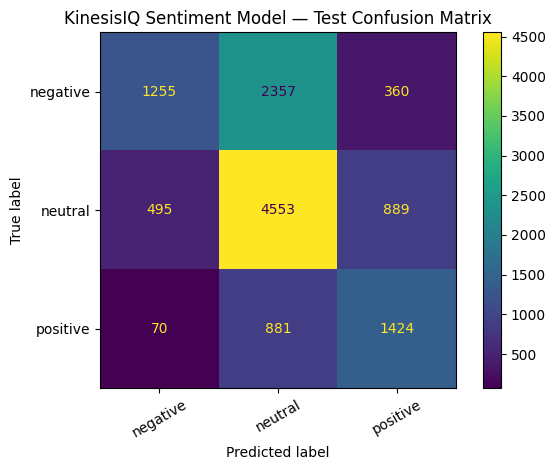

In [ ]:

# CELL 13: Confusion matrix for the selected model

cm = confusion_matrix(
    y_test,
    final_test_pred,
    labels=labels
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(values_format="d")
plt.title("KinesisIQ Sentiment Model — Test Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:

# CELL 14: Extract incorrect predictions

error_df = pd.DataFrame({
    "text": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(final_test_pred)
})

errors = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

print("Total incorrect predictions:", len(errors))

if len(errors) > 0:
    display(errors.head(5))
else:
    print("No test errors found.")


Total incorrect predictions: 5052


,text,actual,predicted
0,@user @user what do these '1/2 naked pics' hav...,neutral,negative
4,"@user Wow,first Hugo Chavez and now Fidel Cast...",negative,neutral
7,Twitter's #ThankYouObama Shows Heartfelt Grati...,positive,neutral
10,An interesting security vulnerability - albeit...,neutral,positive
13,"When Ryan privatizes SS, Medicare, Medicaid, &...",negative,neutral


In [ ]:

# CELL 15: Six original demonstration messages

demo_messages = [
    "I really enjoyed the service today!",
    "The delivery was late and I am very disappointed.",
    "The meeting starts at ten tomorrow.",
    "The food was okay, nothing special.",
    "Fantastic, another two hours waiting for support.",
    "I thought the product would be better, but it works."
]

# Write these expected labels BEFORE running predictions.
expected_labels = [
    "positive",
    "negative",
    "neutral",
    "neutral",
    "negative",
    "neutral"
]

demo_df = pd.DataFrame({
    "message": demo_messages,
    "expected_before_prediction": expected_labels
})

display(demo_df)


,message,expected_before_prediction
0,I really enjoyed the service today!,positive
1,The delivery was late and I am very disappointed.,negative
2,The meeting starts at ten tomorrow.,neutral
3,"The food was okay, nothing special.",neutral
4,"Fantastic, another two hours waiting for support.",negative
5,"I thought the product would be better, but it ...",neutral


In [ ]:

# CELL 16: Reusable sentiment prediction

def predict_sentiment(message):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please enter a non-empty text message.")

    prediction = final_model.predict([message])[0]
    return prediction

# Now generate predictions
demo_df["predicted_sentiment"] = [
    predict_sentiment(message)
    for message in demo_messages
]

display(demo_df)


,message,expected_before_prediction,predicted_sentiment
0,I really enjoyed the service today!,positive,positive
1,The delivery was late and I am very disappointed.,negative,negative
2,The meeting starts at ten tomorrow.,neutral,neutral
3,"The food was okay, nothing special.",neutral,positive
4,"Fantastic, another two hours waiting for support.",negative,positive
5,"I thought the product would be better, but it ...",neutral,positive


In [ ]:

# CELL 17: Try a new message

my_message = "The customer support team solved my problem quickly."
print("Message:", my_message)
print("Predicted sentiment:", predict_sentiment(my_message))


Message: The customer support team solved my problem quickly.
Predicted sentiment: positive


In [ ]:

# CELL 18: Save the final pipeline

MODEL_PATH = "/content/kinesisiq_sentiment_pipeline.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Saved model to:", MODEL_PATH)


Saved model to: /content/kinesisiq_sentiment_pipeline.joblib


In [ ]:

# CELL 19: Reload and verify the saved model

loaded_model = joblib.load(MODEL_PATH)

test_message = "I am happy with the results."

prediction_before = predict_sentiment(test_message)
prediction_after = loaded_model.predict([test_message])[0]

print("Original pipeline prediction:", prediction_before)
print("Reloaded pipeline prediction:", prediction_after)

assert prediction_before == prediction_after
print("Verification passed: predictions match.")


Original pipeline prediction: positive
Reloaded pipeline prediction: positive
Verification passed: predictions match.


In [ ]:
# CELL 20: Create the submission ZIP

from google.colab import drive
import shutil
import zipfile
from pathlib import Path
import os
import urllib.request

drive.mount("/content/drive")

# Define paths locally in case the runtime was restarted
DATA_DIR = "/content/tweeteval_sentiment"
MODEL_PATH = "/content/kinesisiq_sentiment_pipeline.joblib"
STUDENT_ID = " Nokrach Donavin Laly — 179-032 BSE  "

# Ensure dataset directory and files exist locally before copying
if not os.path.exists(DATA_DIR):
    print(f"{DATA_DIR} not found. Re-downloading dataset files...")
    os.makedirs(DATA_DIR, exist_ok=True)
    BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/sentiment/"
    files = [
        "train_text.txt", "train_labels.txt",
        "val_text.txt", "val_labels.txt",
        "test_text.txt", "test_labels.txt",
        "mapping.txt"
    ]
    for filename in files:
        url = BASE_URL + filename
        destination = os.path.join(DATA_DIR, filename)
        urllib.request.urlretrieve(url, destination)
        print("Downloaded:", filename)

# Change this if your notebook is saved elsewhere.
NOTEBOOK_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "KinesisIQ_Week1_Sentiment.ipynb"
)

SUBMISSION_DIR = Path(
    f"/content/KinesisIQ_{STUDENT_ID}_Week1"
)
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# Copy the completed notebook
if not Path(NOTEBOOK_PATH).exists():
    raise FileNotFoundError(
        "Notebook not found. Update NOTEBOOK_PATH to the "
        "actual location of your saved Colab notebook."
    )

shutil.copy2(
    NOTEBOOK_PATH,
    SUBMISSION_DIR / "KinesisIQ_Week1_Sentiment.ipynb"
)

# Copy dataset and model
shutil.copytree(
    DATA_DIR,
    SUBMISSION_DIR / "data",
    dirs_exist_ok=True
)

if os.path.exists(MODEL_PATH):
    shutil.copy2(
        MODEL_PATH,
        SUBMISSION_DIR / "kinesisiq_sentiment_pipeline.joblib"
    )
else:
    print(f"Warning: Model file at {MODEL_PATH} not found. Please run the training cells first to save the model pipeline.")

# Create instructions
readme = """
KinesisIQ Week 1: Sentiment Prediction Prototype

DATA SOURCE
Cardiff NLP TweetEval sentiment dataset:
https://github.com/cardiffnlp/tweeteval/tree/main/datasets/sentiment

CITATION
Barbieri, F., Camacho-Collados, J., Espinosa-Anke, L.,
and Neves, L. (2020). TweetEval: Unified Benchmark and
Comparative Evaluation for Tweet Classification.
Findings of EMNLP 2020.

DATA PREPARATION
The notebook downloads the official train, validation,
and test text and label files. Each text is matched with
its label by line order. mapping.txt provides label names.
Exact training-text overlaps with evaluation data are removed.

MODEL
TF-IDF + Logistic Regression, selected using validation
macro F1. The fitted preprocessing and classifier are
saved together in a Joblib pipeline.

RUNNING
Upload the notebook to Google Colab and run its cells in
order. The original data files are included in the data
folder; the notebook's download cell can fetch fresh copies.
Required packages include pandas, numpy, scikit-learn,
matplotlib and joblib.

DATA TERMS
Consult the TweetEval README and the original source dataset
terms before redistribution or reuse. Public availability
does not necessarily mean all underlying content is unrestricted.

Before submission, include Report.pdf with actual results,
limitations, team members and your individual contribution.
"""

(SUBMISSION_DIR / "README.txt").write_text(
    readme.strip(), encoding="utf-8"
)

# Create ZIP archive
zip_path = f"/content/KinesisIQ_{STUDENT_ID}_Week1.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for file_path in SUBMISSION_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                file_path.relative_to(SUBMISSION_DIR.parent)
            )

print("Created:", zip_path)
print("IMPORTANT: Add your completed Report.pdf before submission.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/tweeteval_sentiment not found. Re-downloading dataset files...
Downloaded: train_text.txt
Downloaded: train_labels.txt
Downloaded: val_text.txt
Downloaded: val_labels.txt
Downloaded: test_text.txt
Downloaded: test_labels.txt
Downloaded: mapping.txt
Created: /content/KinesisIQ_ Nokrach Donavin Laly — 179-032 BSE  _Week1.zip
IMPORTANT: Add your completed Report.pdf before submission.


In [ ]:
import os

model_path = "/content/kinesisiq_sentiment_pipeline.joblib"

print("Model exists:", os.path.exists(model_path))

Model exists: False


In [1]:
from google.colab import files

files.download("/content/kinesisiq_sentiment_pipeline.joblib")

FileNotFoundError: Cannot find file: /content/kinesisiq_sentiment_pipeline.joblib

In [ ]:
readme_text = """
KINESISIQ WEEK 1: SENTIMENT PREDICTION MODEL

PROJECT FILES
- KinesisIQ_Sentiment_Model.ipynb: Completed notebook.
- kinesisiq_sentiment_pipeline.joblib: Trained sentiment model.
- Report.pdf: Project report.

DATASET
Name: Cardiff NLP TweetEval Sentiment
Source: https://github.com/cardiffnlp/tweeteval

HOW TO RUN
1. Open Google Colab.
2. Upload and open the notebook.
3. Run the cells in order.
4. Allow the notebook to download and prepare the dataset.
5. Follow the notebook instructions to train and evaluate the model.

SENTIMENT LABELS
0 = Negative
1 = Neutral
2 = Positive

MODEL
The model uses TF-IDF text features and Logistic Regression.
The selected configuration uses unigrams and bigrams.

To use the saved model, load it using joblib in a compatible
Python environment with the required dependencies installed.
"""

with open("/content/README.txt", "w", encoding="utf-8") as file:
    file.write(readme_text)

print("README.txt created successfully!")

README.txt created successfully!


In [ ]:
from google.colab import files

files.download("/content/README.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>